# CNN Model

In [1]:
import os, shutil, pathlib
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay, classification_report
import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import tensorflow as tf
import numpy as np

from PIL import Image
import time

keras.utils.set_random_seed(2)

base_dir = pathlib.Path("./datasets/dinnerware_mix_background")

In [2]:
'''
remove later? -> add as file to utils

categories = ["bowl", "glass", "mug", "plate"]
splits = ["train", "validation", "test"]
image_extensions = ('.jpg', '.jpeg')

def count_dataset_images():
    for split in splits:
        print(f"\nsplit: {split}")
        total = 0

        for category in categories:
            folder = base_dir / split / category

            image_count = sum(
                1 for filename in os.listdir(folder)
                if filename.lower().endswith(image_extensions)
            )

            total += image_count

            print(f"  {category}: {image_count} images")

        print(f"  Total: {total} images")


count_dataset_images()

'''

'\nremove later? -> add as file to utils\n\ncategories = ["bowl", "glass", "mug", "plate"]\nsplits = ["train", "validation", "test"]\nimage_extensions = (\'.jpg\', \'.jpeg\')\n\ndef count_dataset_images():\n    for split in splits:\n        print(f"\nsplit: {split}")\n        total = 0\n\n        for category in categories:\n            folder = base_dir / split / category\n\n            image_count = sum(\n                1 for filename in os.listdir(folder)\n                if filename.lower().endswith(image_extensions)\n            )\n\n            total += image_count\n\n            print(f"  {category}: {image_count} images")\n\n        print(f"  Total: {total} images")\n\n\ncount_dataset_images()\n\n'

## Data Preprossing

In [3]:
image_size = (224, 224)
batch_size = 32
seed = 123

train_dataset = image_dataset_from_directory(
    base_dir / "train",
    image_size = image_size,
    batch_size = batch_size,
    seed = seed,
)
validation_dataset = image_dataset_from_directory(
    base_dir / "validation",
    image_size = image_size,
    batch_size = batch_size,
    shuffle=False,
    seed = seed,
)
test_dataset = image_dataset_from_directory(
    base_dir / "test",
    image_size = image_size,
    batch_size = batch_size,
    shuffle=False,
    seed = seed,
)

for data_batch, labels_batch in train_dataset:
    print("Data batch shape:", data_batch.shape)
    print("Labels batch shape:", labels_batch.shape)
    break

Found 296 files belonging to 4 classes.
Found 93 files belonging to 4 classes.
Found 95 files belonging to 4 classes.
Data batch shape: (32, 224, 224, 3)
Labels batch shape: (32,)


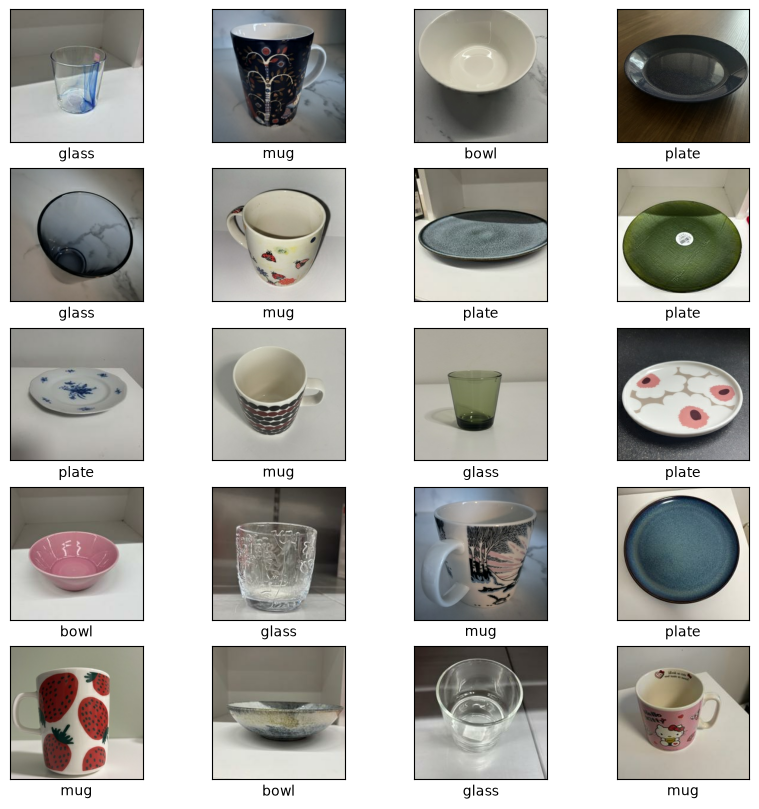

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

class_names = train_dataset.class_names

for images, labels in train_dataset.take(1):
    for i in range(20):
        plt.subplot(5, 4, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.xlabel(class_names[labels[i]])

plt.show()

## Modelling

In [5]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1)
    ]
)

model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),

    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 10, 10, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │        12,804 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 152,228 (594.64 KB)

 Trainable params: 152,228 (594.64 KB)

 Non-trainable params: 0 (0.00 B)

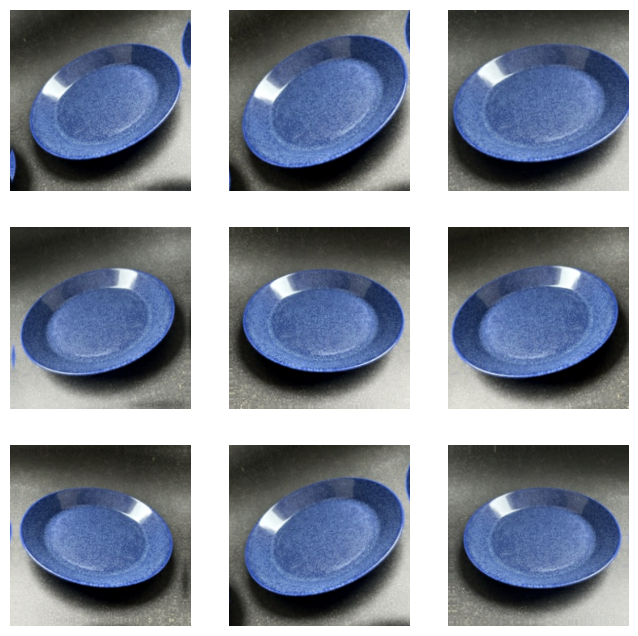

In [6]:
for images, labels in train_dataset.take(1):
    img = images[0:1]

plt.figure(figsize=(8, 8))
for i in range(9):
    aug = data_augmentation(img, training=True)
    plt.subplot(3, 3, i + 1)
    plt.imshow(keras.ops.convert_to_numpy(aug[0]).astype("uint8"))
    plt.axis("off")
plt.show()

## Compile and train the model

In [7]:
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(),
    optimizer=keras.optimizers.Adam(),
    metrics=["accuracy"],
)

In [8]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch_with_augmentation.keras",
        save_best_only=True,
        monitor="val_loss"),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=7, 
        restore_best_weights=True)
]

t0 = time.time()

history = model.fit(
    train_dataset, 
    epochs=70, 
    validation_data=validation_dataset, 
    callbacks=callbacks
)

train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

Epoch 1/70


/opt/anaconda3/envs/keras/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 227ms/step - accuracy: 0.2669 - loss: 1.3942 - val_accuracy: 0.2688 - val_loss: 1.3837
Epoch 2/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 211ms/step - accuracy: 0.2500 - loss: 1.3844 - val_accuracy: 0.3333 - val_loss: 1.3654
Epoch 3/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 214ms/step - accuracy: 0.3649 - loss: 1.3394 - val_accuracy: 0.3978 - val_loss: 1.2699
Epoch 4/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 212ms/step - accuracy: 0.3581 - loss: 1.2936 - val_accuracy: 0.4409 - val_loss: 1.1691
Epoch 5/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 211ms/step - accuracy: 0.4831 - loss: 1.2022 - val_accuracy: 0.5699 - val_loss: 1.1582
Epoch 6/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 210ms/step - accuracy: 0.4966 - loss: 1.1507 - val_accuracy: 0.5484 - val_loss: 1.0828
Epoch 7/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 209ms/step - accuracy: 0.4966 - loss: 1.1259 - val_accuracy: 0.5054 - val_loss: 1.1150
Epoch 8/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 210ms/step - accuracy: 0.4628 - loss: 1.1664 - val_accuracy: 0.4839 - val_

## Learning Curves

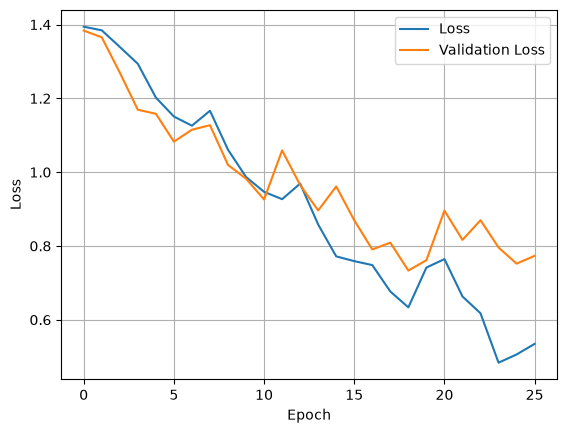

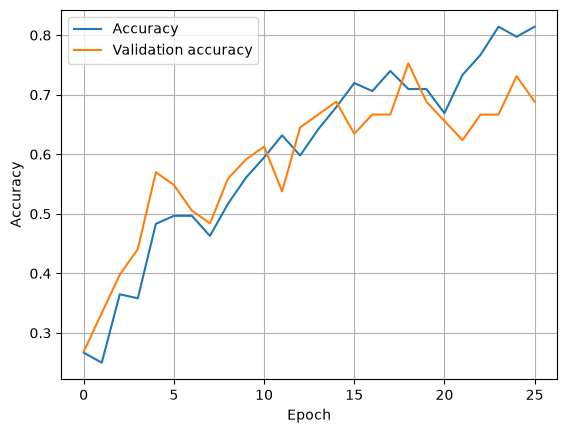

In [9]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid()
plt.show()

## Test perfomance

In [10]:
test_model = keras.models.load_model("convnet_from_scratch_with_augmentation.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)

print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.6842 - loss: 0.9587
Test accuracy: 0.684
Test loss: 0.959


In [11]:
y_true = np.concatenate([y for x, y in test_dataset], axis=0)

probs = test_model.predict(test_dataset)
y_pred = np.argmax(probs, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
              precision    recall  f1-score   support

        bowl       0.84      0.62      0.71        26
       glass       0.59      0.71      0.64        24
         mug       0.63      0.57      0.60        21
       plate       0.71      0.83      0.77        24

    accuracy                           0.68        95
   macro avg       0.69      0.68      0.68        95
weighted avg       0.70      0.68      0.68        95



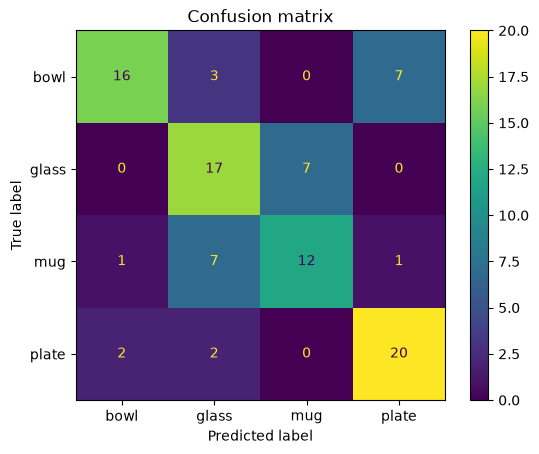

In [12]:
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot()
plt.title("Confusion matrix")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step


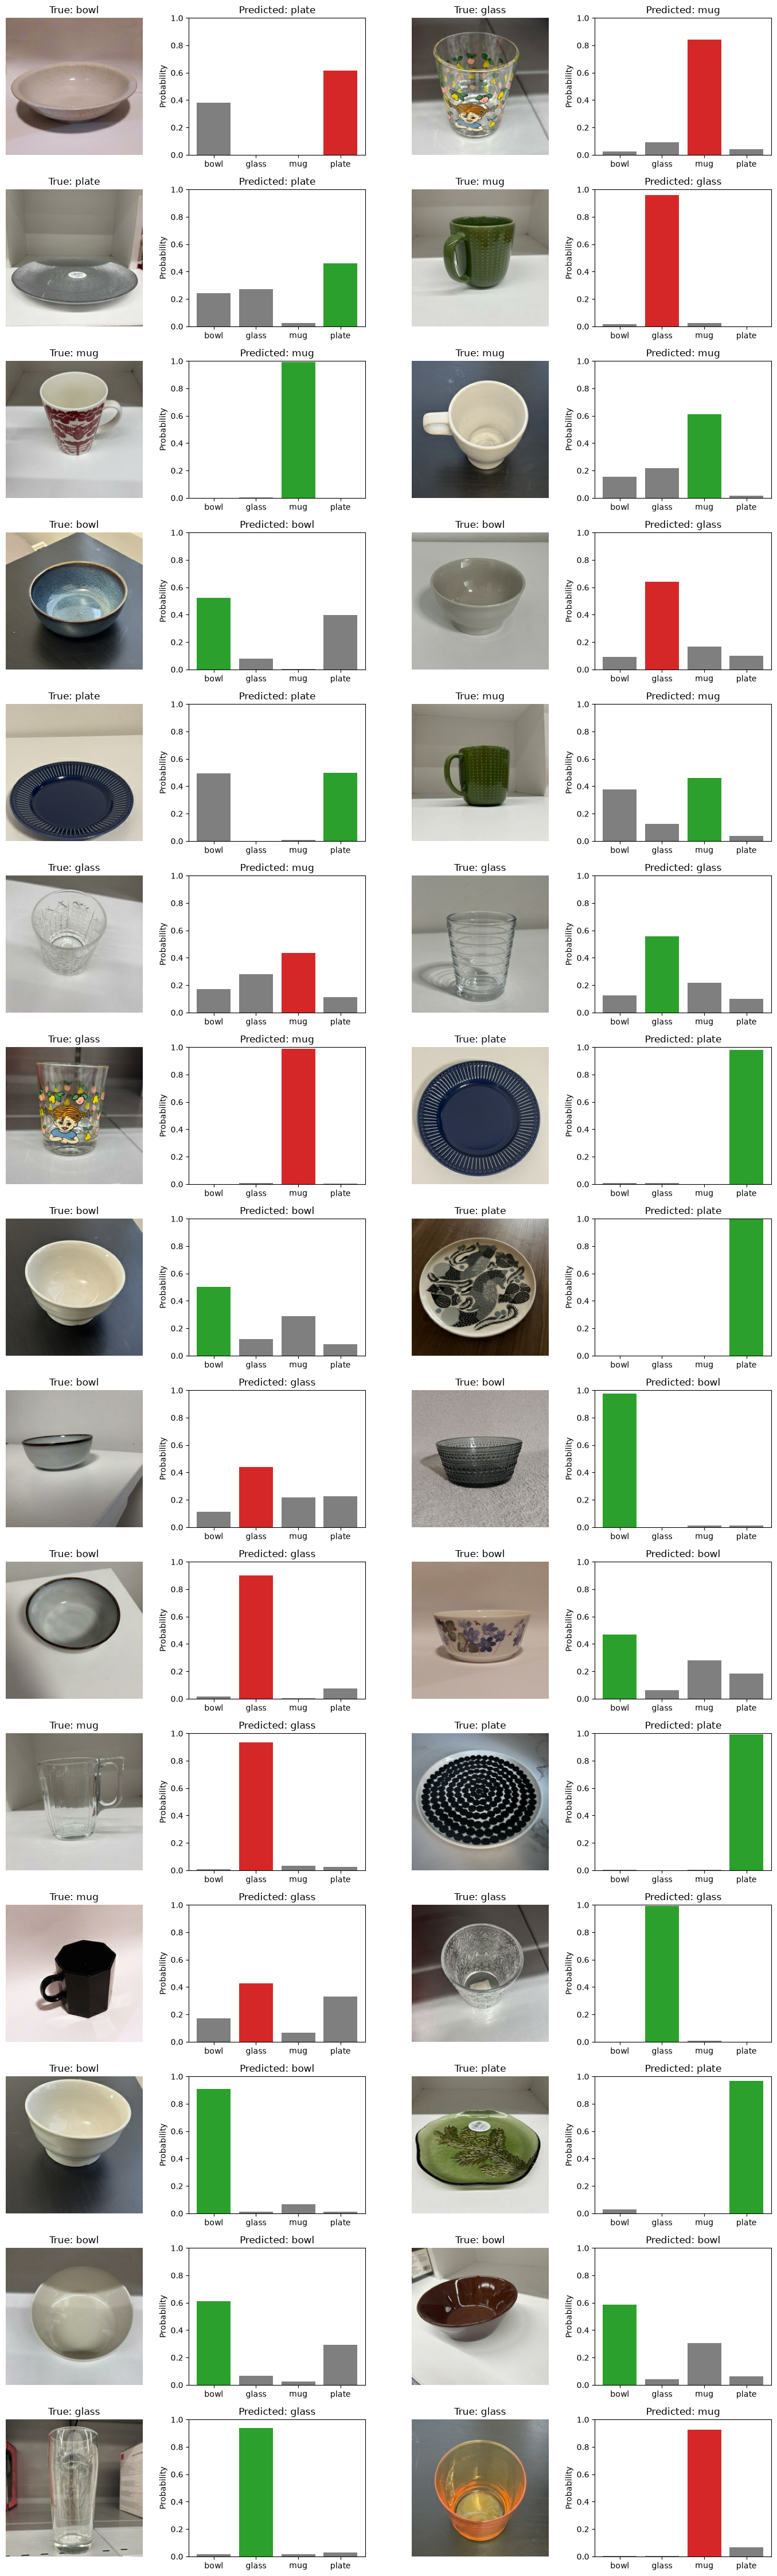

In [13]:
start = 0
images_n = 30
rows = images_n // 2

x, y = next(iter(test_dataset.unbatch().shuffle(1000).batch(images_n)))
probs = test_model.predict(x)

plt.figure(figsize=(14, 3 * rows))

for k in range(images_n):
    i = start + k
    true_label = int(y[i])
    pred_label = int(np.argmax(probs[i]))
    correct = true_label == pred_label

    plt.subplot(rows, 4, 2 * k + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.axis("off")
    plt.title(f"True: {class_names[true_label]}")

    plt.subplot(rows, 4, 2 * k + 2)
    colors = ["tab:gray"] * len(class_names)
    colors[pred_label] = "tab:green" if correct else "tab:red"
    plt.bar(class_names, probs[i], color=colors)
    plt.ylim(0, 1)
    plt.ylabel("Probability")
    plt.title(f"Predicted: {class_names[pred_label]}")

plt.tight_layout()
plt.show()

|Test|Modification|Test accuracy (%)|Test loss|Training time (s)|Conclusion|
|---|---|---|---|---|---|
|Original model|-|55.8|1.102|52.2|Baseline. The model starts to overfit around epoch 4.|
|Version 1|Adds Dropout(0.1)|53.7|1.267|41.3|Slightly worse than the original. Test accuracy is lower, test loss is higher and overfitting is more visible in the learning curves.|
|Version 2|Adds data augmentation: 0.2 for RandomRotation, RandomZoom, RandomContrast|46.3|1.231|63.6|Augmentation at 0.2 is likely too strong for this dataset.|
|Version 3|Modifies data augmentation from 0.2 to 0.1|58.9|1.074|55.5|Better than Version 2. Lower augmentation delays overfitting until it starts around epoch 7.|
|Version 4|Adds Conv2D(16) and MaxPooling2D|64.2|1.284|51.9|Higher test accuracy but test loss also increased. A gap between the training and validation curves appears around epoch 8, but it stays constant until around epoch 20, when it starts to grow and the model begins to overfit.|
|Version 5|Modifies Conv2D(16) to Conv2D(32)|67.4|0.869|68.7|Better on both test accuracy and test loss. Same observation for learning curves as in Version 4. Overfitting starts around epoch 21.|
|Version 6|Modifies parameters for a few Conv2D layers|68.4|0.959|58.6|Test accuracy is about the same as Version 5, test loss is slightly higher and training is faster. The training and validation curves follow each other more closely until overfitting starts around epoch 20.|

**Original model**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    layers.Rescaling(1.0/255),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 1**<br>
**Added layers: Dropout(0.1)**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    layers.Rescaling(1.0/255),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 2**<br>
**Added layers: data_augmentation(0.2), Dropout(0.1)**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 3**<br>
**Added layers: data_augmentation(0.1), Dropout(0.1)**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 4**<br>
**Added layers: data_augmentation(0.1), Conv2D(16) and MaxPooling2D, Dropout(0.1)**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),

    layers.Conv2D(16, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 5**<br>
**Added layers: data_augmentation(0.1), change Conv2D(16) to Conv2D(32), Dropout(0.1)**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),

    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 6**<br>
**Added layers: data_augmentation(0.1), changed values for Conv2D() layers, Dropout(0.1)**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),

    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

In [14]:
## Kirjoitetaan uuden notebookiin

## Dataset description Riikka

## Mallien suorituskyvyn vertailun: Nur

## Kohtaamasi haasteet ja ratkaisut Anni
- Kuvien ottaaminen, taustan päättääminen, esim: värikas tai musta-valkoinen, asento
- Kuvien esikäsittely: rajaus, koon muuttaminen.
- Kuvien laittaminen repoon
- Datan jakaminen: eri hakemistoihin harjoitus-, validointi- ja testidatalle,
- Datan jaon vaikeus: manuaalinen ja automaattinen skriptilla.
- Ylioppimiseen vähentäminen, hyvää tarkkuus, ja loss
- Finetuned mallin ajaamiseen hiitaus: piti miettiä huolellaa mitä muokkaa, ennen kuin ajaa malli.

## Pohdinnan eri mallien soveltuvuudesta ongelmaan Sandra
- CNN malli ei soveltuu koviin hyvin, kun meillä on vähän dataa.
- Feature_Extraction_VGG16 malli antaa parrempia tuloksia, on paljon nopeampi verrattuna CNN malli, mutta tulos ei ollut 100% prosenttin tarkkudella, loss... 
- Fine_tuned malli on erittäin hidas verrattuna muu 2 malli...

## Teköälyn käyttö Anni
- kuvien esitkäsittely skripti
- kuvien alustava jakoon ennen kuin manuaalisesti jaoteltu
- Debuggaus
- Plottaukseen